# AI-Based Hospital Readmission Prediction System

# 06 — Model Evaluation & Final Model Selection

This notebook evaluates all trained machine learning models on the untouched test dataset.

The evaluation focuses on:
- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC
- Confusion Matrix
- ROC Curve

The final model will be selected using the actual test-set results.

# Import Libraries

In [1]:
# Import os for checking folders and file paths
import os

# Import joblib for loading and saving trained models
import joblib

# Import numpy for numerical calculations
import numpy as np

# Import pandas for data manipulation
import pandas as pd

# Import matplotlib for creating visualizations
import matplotlib.pyplot as plt

# Import evaluation metrics from scikit-learn
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    ConfusionMatrixDisplay
)

# Display confirmation message
print("Libraries imported successfully.")

Libraries imported successfully.


# 1. Load the Test Dataset

The test dataset was created during model training and was kept separate from model fitting.

This helps provide an unbiased evaluation of the trained models.

In [2]:
# Load the test features saved during Notebook 05
X_test = joblib.load("artifacts/model_X_test.pkl")

# Load the test target values saved during Notebook 05
y_test = joblib.load("artifacts/model_y_test.pkl")

# Display the shape of the test dataset
print("Test feature shape:", X_test.shape)

# Display the number of test target values
print("Test target shape:", y_test.shape)

Test feature shape: (20354, 48)
Test target shape: (20354,)


In [3]:
# Display the first five rows of the test features
X_test.head()

,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,...,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,total_prior_visits,total_procedures,medications_per_diagnosis
99195,Caucasian,Female,[80-90),1,1,7,4,MC,NaN,40,...,No,No,No,No,No,Ch,Yes,1,40,1.888889
63319,AfricanAmerican,Male,[60-70),1,1,7,5,MC,NaN,29,...,No,No,No,No,No,No,Yes,0,32,3.142857
64536,Caucasian,Female,[70-80),3,22,1,2,MC,Orthopedics-Reconstructive,26,...,No,No,No,No,No,Ch,Yes,3,28,5.800000
13039,Caucasian,Male,[50-60),3,18,1,5,NaN,NaN,43,...,No,No,No,No,No,No,No,1,46,3.777778
37502,AfricanAmerican,Male,[70-80),6,22,17,12,NaN,Pulmonology,77,...,No,No,No,No,No,Ch,Yes,0,83,4.222222


In [4]:
# Display the distribution of the target variable in the test dataset
print("Test Target Distribution:")
print(y_test.value_counts())

Test Target Distribution:
readmitted_binary
0    18083
1     2271
Name: count, dtype: int64


# 3. Load Trained Models

The trained machine learning pipelines from Notebook 05 are loaded.

The models include:
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting
- Tuned Logistic Regression
- Tuned Decision Tree
- Tuned Random Forest

In [5]:
# Load the baseline Logistic Regression model
logistic_model = joblib.load(
    "artifacts/logistic_regression_pipeline.pkl"
)

# Load the baseline Decision Tree model
decision_tree_model = joblib.load(
    "artifacts/decision_tree_pipeline.pkl"
)

# Load the baseline Random Forest model
random_forest_model = joblib.load(
    "artifacts/random_forest_pipeline.pkl"
)

# Load the Gradient Boosting model
gradient_boosting_model = joblib.load(
    "artifacts/gradient_boosting_pipeline.pkl"
)

# Load the tuned Logistic Regression model
tuned_logistic_model = joblib.load(
    "artifacts/tuned_logistic_regression_pipeline.pkl"
)

# Load the tuned Decision Tree model
tuned_decision_tree_model = joblib.load(
    "artifacts/tuned_decision_tree_pipeline.pkl"
)

# Load the tuned Random Forest model
tuned_random_forest_model = joblib.load(
    "artifacts/tuned_random_forest_pipeline.pkl"
)

# Display confirmation
print("All trained models loaded successfully.")

All trained models loaded successfully.


In [6]:
# Store all trained models in a dictionary
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model,
    "Tuned Logistic Regression": tuned_logistic_model,
    "Tuned Decision Tree": tuned_decision_tree_model,
    "Tuned Random Forest": tuned_random_forest_model
}

# Display the names of all loaded models
print("Models loaded for evaluation:")

for model_name in models:
    print("-", model_name)

Models loaded for evaluation:
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting
- Tuned Logistic Regression
- Tuned Decision Tree
- Tuned Random Forest


# 4. Generate Test Predictions

Each trained model will generate predictions for the unseen test dataset.

Two outputs will be generated:
- Predicted class
- Probability of early readmission

Target definition:

`1 = Readmitted within 30 days`

`0 = Not readmitted within 30 days`

In [7]:
# Create dictionaries to store class predictions
predictions = {}

# Create a dictionary to store positive-class probabilities
probabilities = {}

# Generate predictions for every model
for model_name, model in models.items():

    # Generate predicted class labels
    predictions[model_name] = model.predict(X_test)

    # Generate probability of the positive class
    probabilities[model_name] = model.predict_proba(X_test)[:, 1]

# Display confirmation
print("Test predictions generated successfully.")

Test predictions generated successfully.


In [8]:
# Display the first five predictions from every model
for model_name in models:

    # Print the model name
    print("\n", model_name)

    # Display the first five predicted classes
    print(predictions[model_name][:5])


 Logistic Regression
[1 0 0 1 0]

 Decision Tree
[0 0 0 0 0]

 Random Forest
[0 0 0 0 0]

 Gradient Boosting
[0 0 0 0 0]

 Tuned Logistic Regression
[1 0 0 1 1]

 Tuned Decision Tree
[1 0 1 0 1]

 Tuned Random Forest
[1 0 0 1 0]


# 5. Calculate Evaluation Metrics

The following metrics will be calculated for every model:

- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC

F1-Score and Recall are particularly important because the target
classes are imbalanced and early readmissions need to be detected.

In [9]:
# Create an empty list to store model evaluation results
evaluation_results = []

# Evaluate every trained model
for model_name in models:

    # Get the predicted class labels
    y_pred = predictions[model_name]

    # Get the predicted probabilities
    y_prob = probabilities[model_name]

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    # Calculate precision
    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    # Calculate recall
    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    # Calculate F1-score
    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    # Calculate ROC-AUC
    roc_auc = roc_auc_score(
        y_test,
        y_prob
    )

    # Store all metrics for the current model
    evaluation_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    })

# Convert the results into a DataFrame
results_df = pd.DataFrame(evaluation_results)

# Display the evaluation results
results_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.642085,0.165733,0.547336,0.254426,0.644120
1,Decision Tree,0.789673,0.172211,0.232497,0.197864,0.546072
2,Random Forest,0.888621,0.611111,0.004844,0.009611,0.661361
3,Gradient Boosting,0.888572,0.534884,0.010128,0.019879,0.681389
4,Tuned Logistic Regression,0.659035,0.174634,0.551739,0.265297,0.660719
5,Tuned Decision Tree,0.630539,0.172551,0.608983,0.268909,0.658901
6,Tuned Random Forest,0.719564,0.194271,0.480845,0.276736,0.670287


In [10]:
# Create a copy of the results for formatted display
results_display = results_df.copy()

# Define the metric columns
metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

# Round the metric values to four decimal places
results_display[metric_columns] = results_display[
    metric_columns
].round(4)

# Display the formatted results
results_display

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.6421,0.1657,0.5473,0.2544,0.6441
1,Decision Tree,0.7897,0.1722,0.2325,0.1979,0.5461
2,Random Forest,0.8886,0.6111,0.0048,0.0096,0.6614
3,Gradient Boosting,0.8886,0.5349,0.0101,0.0199,0.6814
4,Tuned Logistic Regression,0.6590,0.1746,0.5517,0.2653,0.6607
5,Tuned Decision Tree,0.6305,0.1726,0.6090,0.2689,0.6589
6,Tuned Random Forest,0.7196,0.1943,0.4808,0.2767,0.6703


# 6. Classification Report

The classification report provides precision, recall and F1-score
for both target classes.

This gives a more detailed view of model performance than accuracy alone.

In [11]:
# Generate a classification report for every model
for model_name in models:

    # Print the model name
    print("=" * 70)
    print(model_name)
    print("=" * 70)

    # Generate the classification report
    report = classification_report(
        y_test,
        predictions[model_name],
        zero_division=0
    )

    # Display the classification report
    print(report)

Logistic Regression
              precision    recall  f1-score   support

           0       0.92      0.65      0.76     18083
           1       0.17      0.55      0.25      2271

    accuracy                           0.64     20354
   macro avg       0.54      0.60      0.51     20354
weighted avg       0.84      0.64      0.71     20354

Decision Tree
              precision    recall  f1-score   support

           0       0.90      0.86      0.88     18083
           1       0.17      0.23      0.20      2271

    accuracy                           0.79     20354
   macro avg       0.54      0.55      0.54     20354
weighted avg       0.82      0.79      0.80     20354

Random Forest
              precision    recall  f1-score   support

           0       0.89      1.00      0.94     18083
           1       0.61      0.00      0.01      2271

    accuracy                           0.89     20354
   macro avg       0.75      0.50      0.48     20354
weighted avg       0.86   

# 7. Confusion Matrix

A confusion matrix shows four types of predictions:

- True Positive (TP)
- True Negative (TN)
- False Positive (FP)
- False Negative (FN)

False negatives are important in this project because they represent
patients who were readmitted early but were not identified by the model.

In [14]:
# Generate and display the confusion matrix values for every model
for model_name in models:

    # Calculate the confusion matrix
    cm = confusion_matrix(
        y_test,
        predictions[model_name]
    )

    # Display the model name
    print("\n", model_name)

    # Display the confusion matrix
    print(cm)


 Logistic Regression
[[11826  6257]
 [ 1028  1243]]

 Decision Tree
[[15545  2538]
 [ 1743   528]]

 Random Forest
[[18076     7]
 [ 2260    11]]

 Gradient Boosting
[[18063    20]
 [ 2248    23]]

 Tuned Logistic Regression
[[12161  5922]
 [ 1018  1253]]

 Tuned Decision Tree
[[11451  6632]
 [  888  1383]]

 Tuned Random Forest
[[13554  4529]
 [ 1179  1092]]


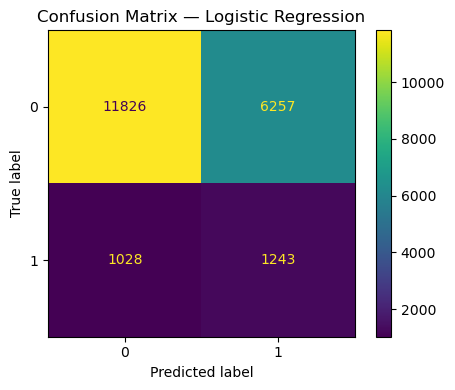

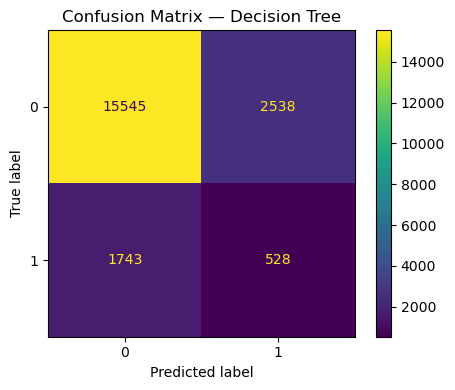

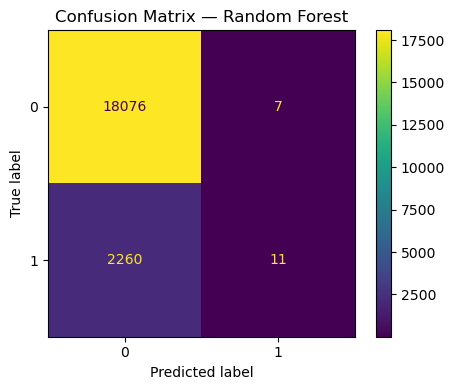

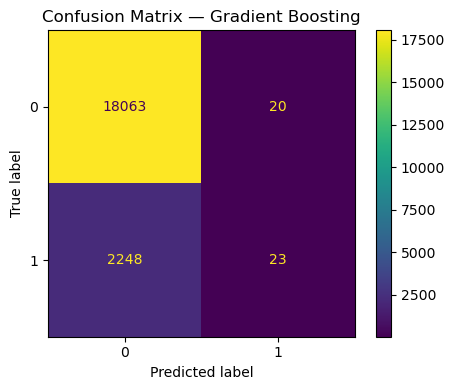

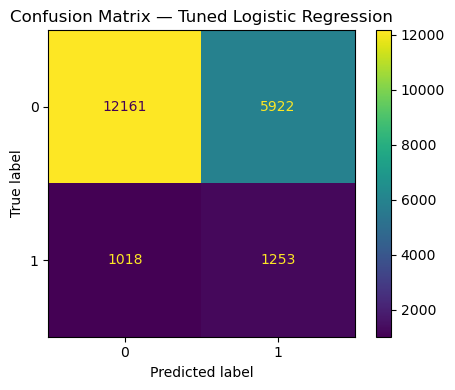

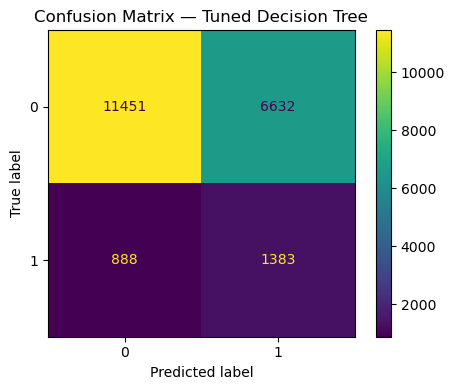

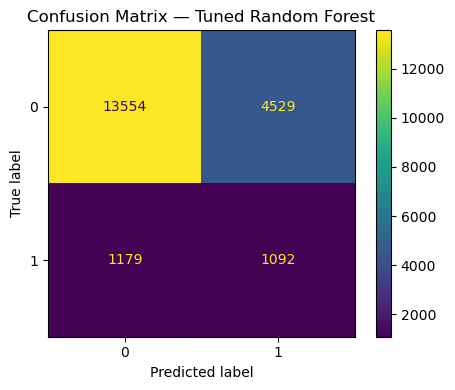

In [15]:
# Create a visual confusion matrix for every model
for model_name in models:

    # Create a new figure
    fig, ax = plt.subplots(figsize=(5, 4))

    # Display the confusion matrix
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions[model_name],
        ax=ax
    )

    # Add a title
    ax.set_title(
        f"Confusion Matrix — {model_name}"
    )

    # Adjust the layout
    plt.tight_layout()

    # Display the plot
    plt.show()

# 8. ROC Curve

ROC curves are used to compare the ability of different models
to distinguish between:

- Early readmission
- No early readmission

The ROC-AUC value represents the area under the ROC curve.

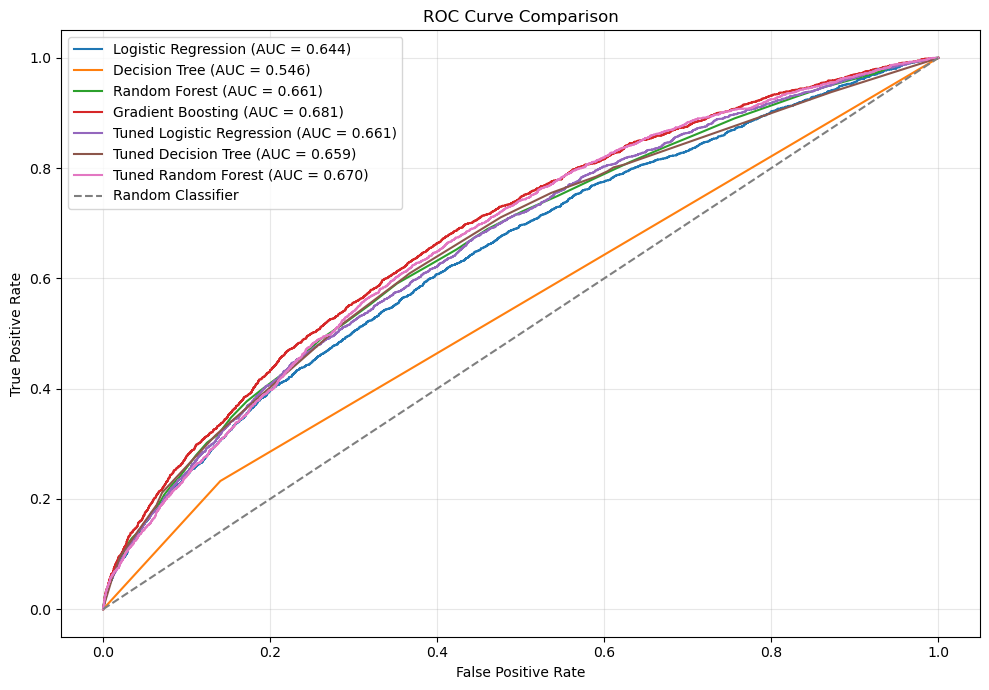

In [16]:
# Create a figure for ROC curve comparison
plt.figure(figsize=(10, 7))

# Plot the ROC curve for every model
for model_name in models:

    # Calculate False Positive Rate and True Positive Rate
    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities[model_name]
    )

    # Calculate ROC-AUC
    auc_value = roc_auc_score(
        y_test,
        probabilities[model_name]
    )

    # Plot the ROC curve
    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_value:.3f})"
    )

# Add the random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

# Add x-axis label
plt.xlabel("False Positive Rate")

# Add y-axis label
plt.ylabel("True Positive Rate")

# Add chart title
plt.title("ROC Curve Comparison")

# Display the legend
plt.legend()

# Add a light grid
plt.grid(alpha=0.3)

# Adjust the layout
plt.tight_layout()

# Display the ROC curve
plt.show()

# 9. Model Comparison

The performance of all trained models is compared using their
evaluation metrics.

F1-Score will be used as the primary comparison metric because
the target variable is imbalanced.

Recall and ROC-AUC will also be considered.

In [17]:
# Sort all models according to their F1-score
f1_comparison = results_df.sort_values(
    by="F1-Score",
    ascending=False
)

# Display the model comparison
f1_comparison[
    [
        "Model",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ]
]

,Model,Precision,Recall,F1-Score,ROC-AUC
6,Tuned Random Forest,0.194271,0.480845,0.276736,0.670287
5,Tuned Decision Tree,0.172551,0.608983,0.268909,0.658901
4,Tuned Logistic Regression,0.174634,0.551739,0.265297,0.660719
0,Logistic Regression,0.165733,0.547336,0.254426,0.644120
1,Decision Tree,0.172211,0.232497,0.197864,0.546072
3,Gradient Boosting,0.534884,0.010128,0.019879,0.681389
2,Random Forest,0.611111,0.004844,0.009611,0.661361


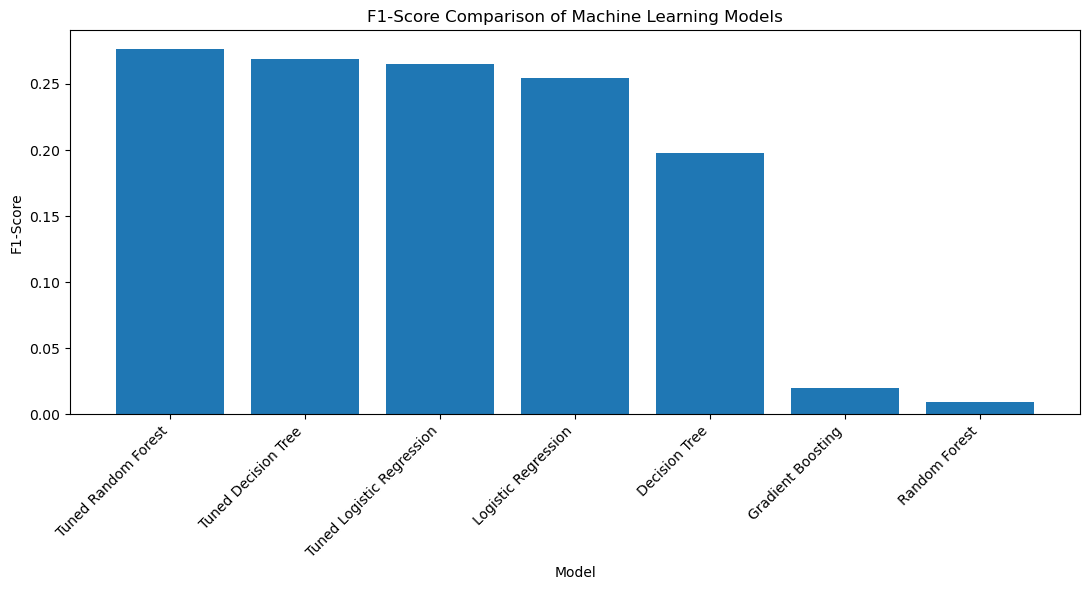

In [18]:
# Create a bar chart for F1-score comparison
plt.figure(figsize=(11, 6))

# Plot the F1-score for every model
plt.bar(
    f1_comparison["Model"],
    f1_comparison["F1-Score"]
)

# Add chart title
plt.title("F1-Score Comparison of Machine Learning Models")

# Add x-axis label
plt.xlabel("Model")

# Add y-axis label
plt.ylabel("F1-Score")

# Rotate model names for readability
plt.xticks(
    rotation=45,
    ha="right"
)

# Adjust layout
plt.tight_layout()

# Display the chart
plt.show()

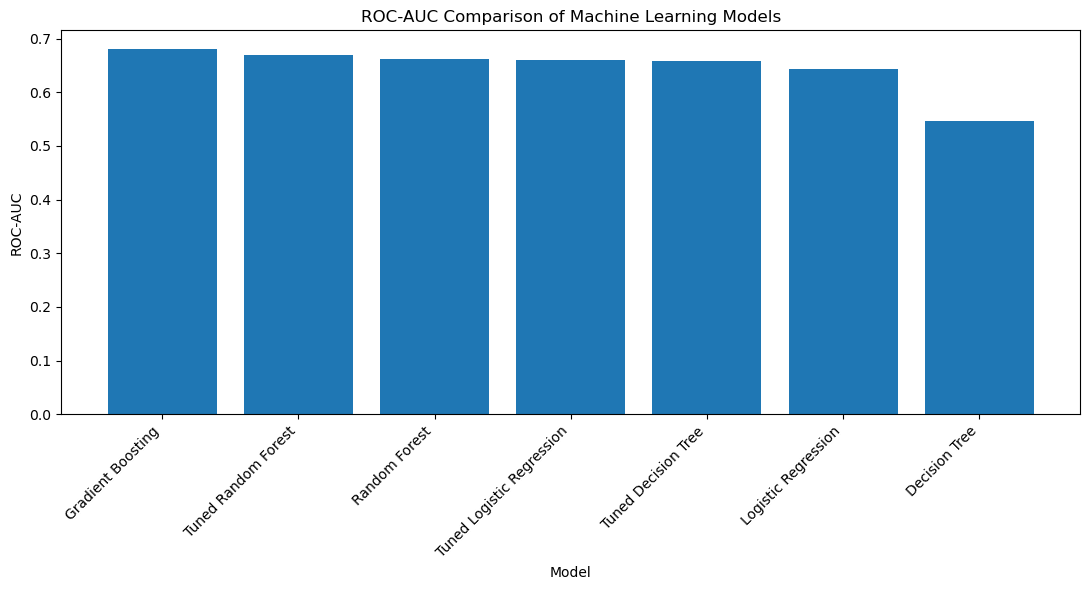

In [19]:
# Sort models according to ROC-AUC
roc_comparison = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

# Create the ROC-AUC comparison chart
plt.figure(figsize=(11, 6))

# Plot ROC-AUC values
plt.bar(
    roc_comparison["Model"],
    roc_comparison["ROC-AUC"]
)

# Add chart title
plt.title("ROC-AUC Comparison of Machine Learning Models")

# Add x-axis label
plt.xlabel("Model")

# Add y-axis label
plt.ylabel("ROC-AUC")

# Rotate model names
plt.xticks(
    rotation=45,
    ha="right"
)

# Adjust layout
plt.tight_layout()

# Display the chart
plt.show()

# 10. Select Final Model

The final model will be selected using the following evaluation rule:

1. Primary criterion: F1-Score
2. First tie-breaker: Recall
3. Second tie-breaker: ROC-AUC

The selection is based on the actual performance obtained on the
held-out test dataset.

In [20]:
# Sort the models using the documented selection criteria
final_model_ranking = results_df.sort_values(
    by=[
        "F1-Score",
        "Recall",
        "ROC-AUC"
    ],
    ascending=[
        False,
        False,
        False
    ]
).reset_index(drop=True)

# Display the final model ranking
final_model_ranking

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Tuned Random Forest,0.719564,0.194271,0.480845,0.276736,0.670287
1,Tuned Decision Tree,0.630539,0.172551,0.608983,0.268909,0.658901
2,Tuned Logistic Regression,0.659035,0.174634,0.551739,0.265297,0.660719
3,Logistic Regression,0.642085,0.165733,0.547336,0.254426,0.644120
4,Decision Tree,0.789673,0.172211,0.232497,0.197864,0.546072
5,Gradient Boosting,0.888572,0.534884,0.010128,0.019879,0.681389
6,Random Forest,0.888621,0.611111,0.004844,0.009611,0.661361


In [21]:
# Select the first model from the ranked results
final_model_name = final_model_ranking.loc[0, "Model"]

# Display the selected final model
print("Final Selected Model:", final_model_name)

Final Selected Model: Tuned Random Forest


In [22]:
# Retrieve the selected final model
final_model = models[final_model_name]

# Retrieve the selected model's evaluation results
final_model_results = results_df[
    results_df["Model"] == final_model_name
].iloc[0]

# Display the final model performance
print("Final Model:", final_model_name)
print("Accuracy:", round(final_model_results["Accuracy"], 4))
print("Precision:", round(final_model_results["Precision"], 4))
print("Recall:", round(final_model_results["Recall"], 4))
print("F1-Score:", round(final_model_results["F1-Score"], 4))
print("ROC-AUC:", round(final_model_results["ROC-AUC"], 4))

Final Model: Tuned Random Forest
Accuracy: 0.7196
Precision: 0.1943
Recall: 0.4808
F1-Score: 0.2767
ROC-AUC: 0.6703


# 11. Feature Importance / Coefficient Analysis

The selected model will be analyzed to identify the features that
contribute most strongly to its predictions.

For tree-based models, feature importance values are used.

For linear models, model coefficients are examined.

These values represent model-level associations and should not be
interpreted as causal relationships.

In [23]:
# Access the final estimator from the trained pipeline
final_estimator = final_model.named_steps["model"]

# Display the type of final estimator
print("Final estimator:")
print(type(final_estimator))

Final estimator:
<class 'sklearn.ensemble._forest.RandomForestClassifier'>


In [24]:
# Access the preprocessing component of the final pipeline
final_preprocessor = final_model.named_steps["preprocessor"]

# Extract the transformed feature names
try:
    transformed_features = (
        final_preprocessor.get_feature_names_out()
    )

    # Display the number of transformed features
    print(
        "Number of transformed features:",
        len(transformed_features)
    )

except Exception as error:

    # Display an error message if feature names cannot be extracted
    print(
        "Feature names could not be extracted:",
        error
    )

Number of transformed features: 2361


In [25]:
# Check whether the selected model provides feature importance
if hasattr(final_estimator, "feature_importances_"):

    # Store feature importance values
    importance_values = final_estimator.feature_importances_

    # Create a DataFrame for feature importance
    feature_importance_df = pd.DataFrame({
        "Feature": transformed_features,
        "Importance": importance_values
    })

    # Sort features from highest to lowest importance
    feature_importance_df = feature_importance_df.sort_values(
        by="Importance",
        ascending=False
    )

    # Display the top 20 features
    feature_importance_df.head(20)

else:

    # Display a message when feature importance is unavailable
    print(
        "Feature importance is not available for the selected model."
    )

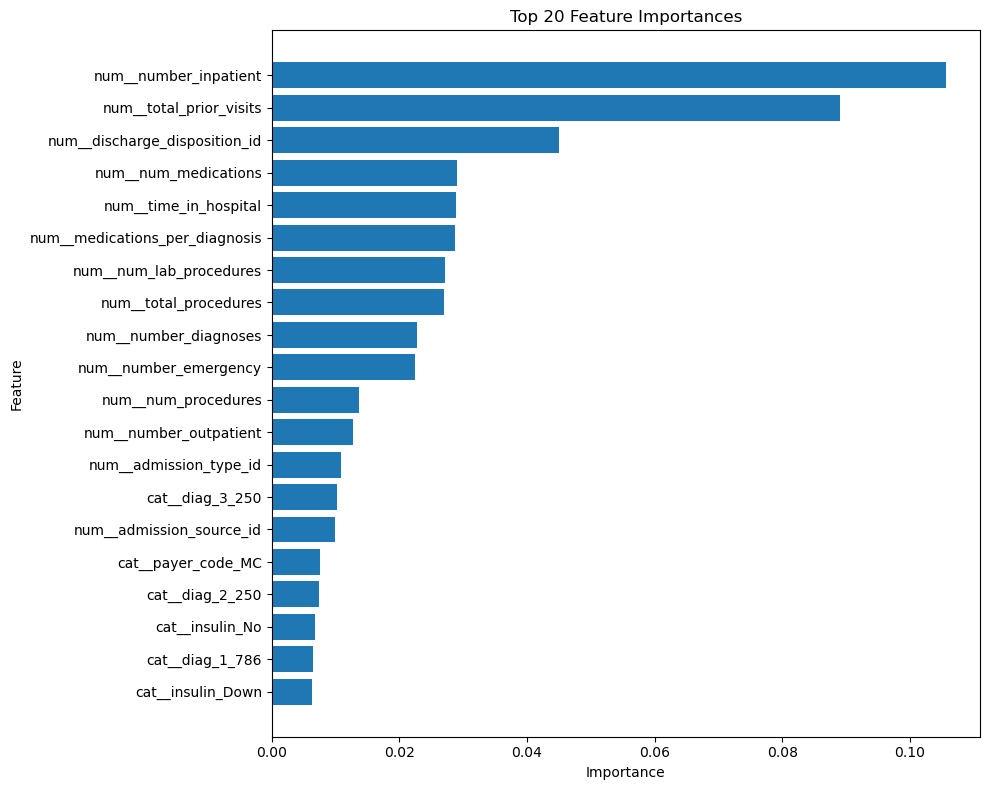

In [26]:
# Check whether feature importance was successfully created
if "feature_importance_df" in globals():

    # Select the top 20 features
    top_features = feature_importance_df.head(20)

    # Create the feature importance plot
    plt.figure(figsize=(10, 8))

    # Plot the features in reverse order
    plt.barh(
        top_features["Feature"][::-1],
        top_features["Importance"][::-1]
    )

    # Add chart title
    plt.title("Top 20 Feature Importances")

    # Add axis labels
    plt.xlabel("Importance")
    plt.ylabel("Feature")

    # Adjust layout
    plt.tight_layout()

    # Display the plot
    plt.show()

else:

    # Display a message when plotting is not possible
    print(
        "Feature importance plot is not available."
    )

In [27]:
# Check whether the selected model contains coefficients
if hasattr(final_estimator, "coef_"):

    # Extract the coefficient values
    coefficient_values = final_estimator.coef_[0]

    # Create a DataFrame for coefficients
    coefficient_df = pd.DataFrame({
        "Feature": transformed_features,
        "Coefficient": coefficient_values
    })

    # Calculate the absolute value of coefficients
    coefficient_df["Absolute_Coefficient"] = (
        coefficient_df["Coefficient"].abs()
    )

    # Sort features by coefficient magnitude
    coefficient_df = coefficient_df.sort_values(
        by="Absolute_Coefficient",
        ascending=False
    )

    # Display the top 20 coefficients
    coefficient_df.head(20)

else:

    # Display a message when coefficients are unavailable
    print(
        "Coefficients are not available for the selected model."
    )

Coefficients are not available for the selected model.


# 12. Save Evaluation Results

The model evaluation results will be saved as a CSV file.

This file can later be used for:
- Research paper
- Project report
- Presentation

In [28]:
# Save the evaluation results as a CSV file
results_df.to_csv(
    "artifacts/model_evaluation_results.csv",
    index=False
)

# Display confirmation
print(
    "Model evaluation results saved successfully."
)

Model evaluation results saved successfully.


# 13. Save Final Model

The selected final model pipeline is saved in the artifacts folder.

The saved pipeline contains the preprocessing steps and trained model,
so it can later be used directly by the deployment application.

In [29]:
# Save the selected final model pipeline
joblib.dump(
    final_model,
    "artifacts/final_readmission_model.pkl"
)

# Display confirmation
print(
    "Final readmission model saved successfully."
)

Final readmission model saved successfully.


# 14. Save Final Model Name

The name of the selected final model is saved separately.

This information will be useful during deployment and documentation.

In [30]:
# Save the final model name into a text file
with open(
    "artifacts/final_model_name.txt",
    "w",
    encoding="utf-8"
) as file:

    # Write the selected model name
    file.write(final_model_name)

# Display confirmation
print(
    "Final model name saved successfully."
)

Final model name saved successfully.


# 15. Save Model Input Columns

The deployment application must know which input columns are expected
by the trained model.

The model input columns are therefore saved for later use.

In [31]:
# Get the input column names used by the model
model_input_columns = list(X_test.columns)

# Save the input column names
joblib.dump(
    model_input_columns,
    "artifacts/model_input_columns.pkl"
)

# Display the number of input columns
print(
    "Number of model input columns:",
    len(model_input_columns)
)

# Display confirmation
print(
    "Model input columns saved successfully."
)

Number of model input columns: 48
Model input columns saved successfully.


# 16. Verify Saved Files

The important output files created in this notebook are checked
to make sure they exist in the artifacts folder.

In [32]:
# Define the files that should have been created
required_files = [
    "artifacts/final_readmission_model.pkl",
    "artifacts/final_model_name.txt",
    "artifacts/model_evaluation_results.csv",
    "artifacts/model_input_columns.pkl"
]

# Check every required file
for file_path in required_files:

    # Check whether the file exists
    if os.path.exists(file_path):

        # Display successful verification
        print("✓ Found:", file_path)

    else:

        # Display missing file warning
        print("✗ Missing:", file_path)

✓ Found: artifacts/final_readmission_model.pkl
✓ Found: artifacts/final_model_name.txt
✓ Found: artifacts/model_evaluation_results.csv
✓ Found: artifacts/model_input_columns.pkl


# 17. Verify Final Model

The saved final model is loaded again to confirm that it can be
successfully restored and used for prediction.

In [33]:
# Load the saved final model
loaded_final_model = joblib.load(
    "artifacts/final_readmission_model.pkl"
)

# Generate predictions for five test records
verification_predictions = loaded_final_model.predict(
    X_test.head(5)
)

# Display the verification predictions
print(
    "Verification predictions:",
    verification_predictions
)

# Display confirmation
print(
    "Saved final model loaded and verified successfully."
)

Verification predictions: [1 0 0 1 0]
Saved final model loaded and verified successfully.


# 18. Final Evaluation Summary

The final selected model and its actual test-set performance are
displayed below.

The values are generated directly from the evaluation results and
are not manually entered.

In [34]:
# Create a summary dictionary using the actual evaluation results
final_summary = {
    "Final Model": final_model_name,
    "Accuracy": round(
        final_model_results["Accuracy"], 4
    ),
    "Precision": round(
        final_model_results["Precision"], 4
    ),
    "Recall": round(
        final_model_results["Recall"], 4
    ),
    "F1-Score": round(
        final_model_results["F1-Score"], 4
    ),
    "ROC-AUC": round(
        final_model_results["ROC-AUC"], 4
    )
}

# Convert the summary into a DataFrame
final_summary_df = pd.DataFrame(
    [final_summary]
)

# Display the final summary
final_summary_df

,Final Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Tuned Random Forest,0.7196,0.1943,0.4808,0.2767,0.6703


# 19. Conclusion

All trained machine learning models were evaluated using the
held-out test dataset.

The models were compared using Accuracy, Precision, Recall,
F1-Score and ROC-AUC.

Confusion matrices and ROC curves were also used to understand
model performance.

The final model was selected using the documented criteria:
F1-Score, followed by Recall and ROC-AUC.

The selected model has been saved as:

`artifacts/final_readmission_model.pkl`

The complete evaluation results have been saved as:

`artifacts/model_evaluation_results.csv`

The saved final model will be used in the deployment stage.

# 20. Completion Check

In [35]:
# Display a final completion message
print("=" * 60)
print("NOTEBOOK 06 COMPLETED SUCCESSFULLY")
print("=" * 60)

# Display the selected final model
print("Final Model:", final_model_name)

# Display the number of evaluated models
print("Models Evaluated:", len(models))

# Display the final model file
print(
    "Final Model File:",
    "artifacts/final_readmission_model.pkl"
)

# Display the evaluation results file
print(
    "Evaluation Results File:",
    "artifacts/model_evaluation_results.csv"
)

NOTEBOOK 06 COMPLETED SUCCESSFULLY
Final Model: Tuned Random Forest
Models Evaluated: 7
Final Model File: artifacts/final_readmission_model.pkl
Evaluation Results File: artifacts/model_evaluation_results.csv
